# Weather Report

**Question:** How has the climate changed in Samsun, Milan and Istanbul since 1940?

**Data:** daily temperature and precipitation from the Open-Meteo Historical Weather API (1940-2025), downloaded with `src/data_loader.py`.

**Method:** clean the data with pandas, compute anomalies, trends and hot days with numpy, and visualise the results with matplotlib.

In [1]:
from src.data_processing import load_weather_data, clean_weather_data, yearly_summary
from src.analysis import add_anomalies, temperature_trend , count_hot_days
from src.plots import plot_anomalies, plot_monthly_heatmap , plot_hot_days

data = clean_weather_data(load_weather_data())
summary = add_anomalies(yearly_summary(data))
data.head()

,date,temp_mean,temp_max,temp_min,precipitation,city,year,month
1,1940-01-02,1.4,2.5,-0.0,4.7,Istanbul,1940,1
2,1940-01-03,-1.6,-0.0,-3.8,2.7,Istanbul,1940,1
3,1940-01-04,-0.6,1.9,-4.3,0.0,Istanbul,1940,1
4,1940-01-05,2.6,4.0,0.7,0.0,Istanbul,1940,1
5,1940-01-06,4.3,5.4,3.3,24.9,Istanbul,1940,1


In [2]:
for city in summary["city"].unique():
    print(city, round(temperature_trend(summary, city), 2), "°C per decade")

Istanbul 0.13 °C per decade
Milan 0.31 °C per decade
Samsun 0.17 °C per decade


## Temperature anomaly

How much warmer or colder each year is compared with 1961-1990.

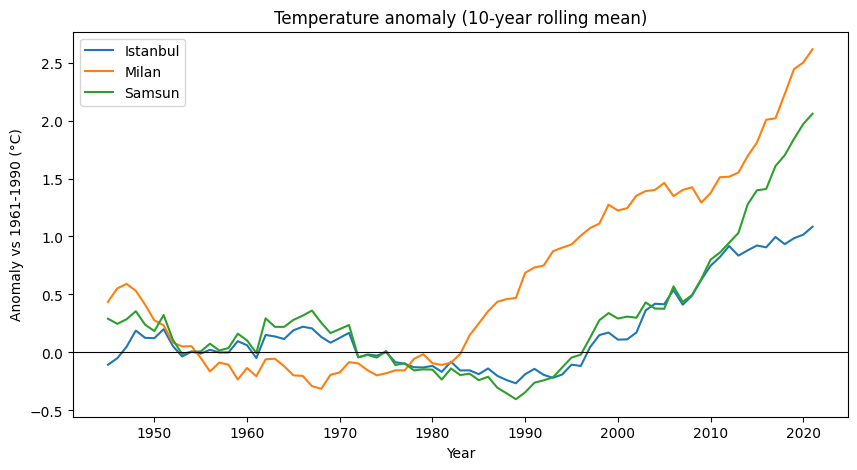

In [3]:
plot_anomalies(summary);

## Monthly mean temperature

The heatmaps show the seasonal cycle of each city across the years.

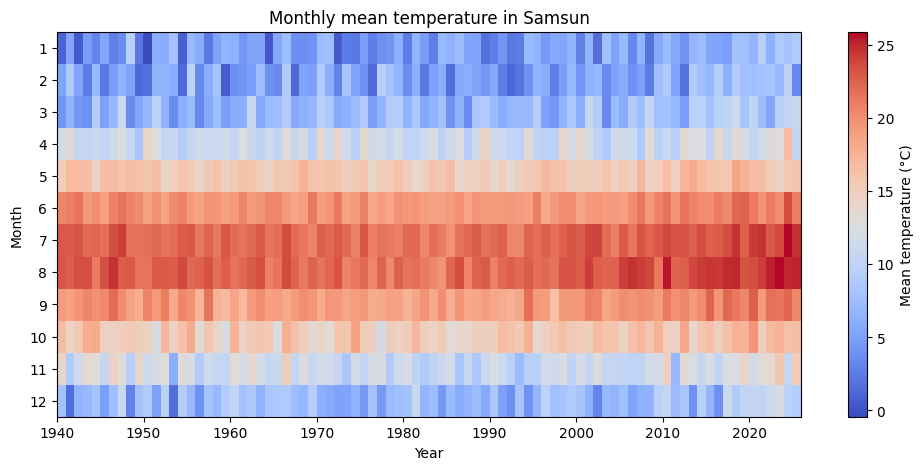

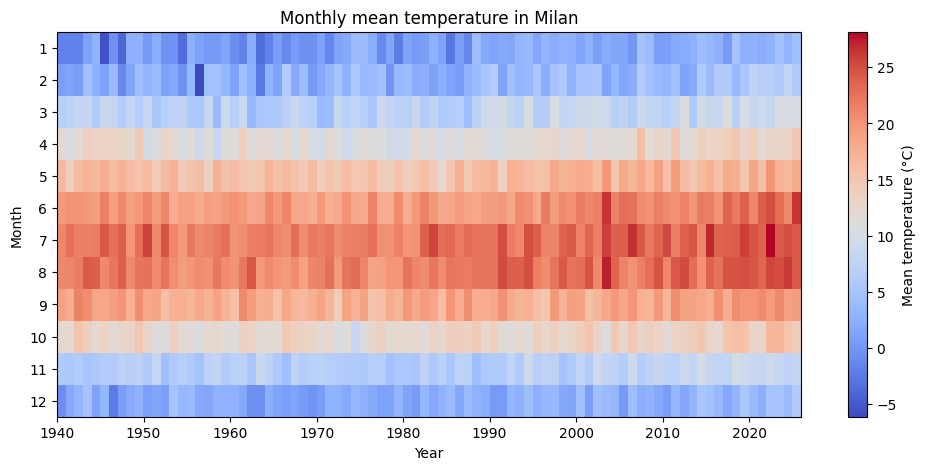

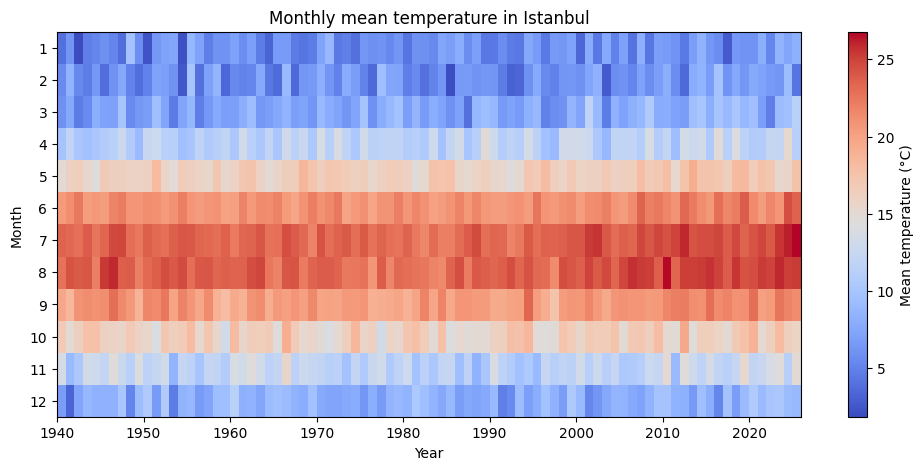

In [4]:
for city in ["Samsun", "Milan", "Istanbul"]:
    plot_monthly_heatmap(data, city)

## Hot days

Number of days per year with a maximum temperature above 30 °C (average of each decade).

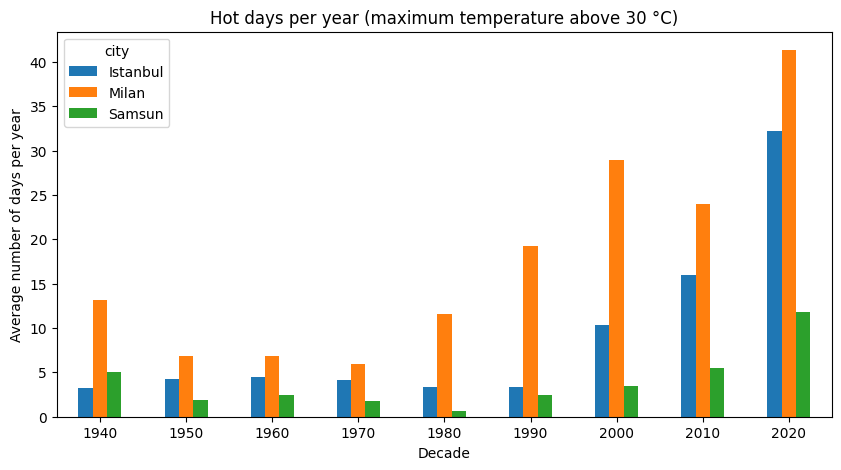

In [5]:
hot_days = count_hot_days(data)
plot_hot_days(hot_days);

## Conclusions

- All three cities are warmer today than in the 1961-1990 reference period.
- Over 1940-2025, the warming trend is about +0.31 °C per decade in Milan, +0.17 in Samsun and +0.13 in Istanbul.
- The change is not constant: temperatures were stable until about 1990 and then increased quickly.
- Hot days (maximum temperature above 30 °C) became much more frequent: in 2011-2025 Milan has about 31 hot days per year, against about 8 in 1961-1990.
- In the heatmaps the seasonal cycle is much larger than the long-term change, so warming is easier to see in the anomaly plot.

**Data:** Open-Meteo Historical Weather API (model-based reanalysis data, not direct station measurements).